# Семинар 11. Кластеризация

На лекции мы разобрали задачу кластеризации: объекты не размечены, и нужно разбить их на группы похожих. Сегодня посмотрим на алгоритмы в деле:

1. K-means: как работает, что будет при неверном числе кластеров и неудачной инициализации.
2. Метрики качества: внутренние (силуэт, инерция) и внешние (ARI, гомогенность, полнота, V-мера), а также зачем масштабировать признаки.
3. DBSCAN: роль `eps` и `min_samples`, выбор `eps` по графику k-расстояний, кластеры сложной формы.
4. Иерархическая кластеризация: дендрограмма, разрез дерева, разные способы связи.
5. HDBSCAN: кластеры разной плотности.
6. Сравнение всех алгоритмов на наборах данных разной формы.

Во всех примерах фиксируем `random_state`, чтобы результаты совпадали от запуска к запуску.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering, HDBSCAN
from sklearn.datasets import make_blobs, make_moons, make_circles, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, adjusted_rand_score, homogeneity_score,
                             completeness_score, v_measure_score)

plt.rcParams['figure.figsize'] = [8, 6]

Вспомогательная функция для рисования. У DBSCAN и HDBSCAN шумовые точки получают метку $-1$: красим их серым, чтобы отличать от кластеров.

In [2]:
PALETTE = np.array(['#4472C4', '#ED7D31', '#70AD47', '#FFC000', '#7030A0',
                    '#00B0F0', '#C00000', '#A5A5A5', '#264478', '#9E480E'])

def plot_clusters(X, labels, ax=None, title=None, centers=None, s=15):
    """Точки, раскрашенные по кластерам; шум (метка -1) серым."""
    ax = ax or plt.gca()
    labels = np.asarray(labels)
    colors = np.array(['#D0D0D0' if l < 0 else PALETTE[l % len(PALETTE)] for l in labels])
    ax.scatter(X[:, 0], X[:, 1], c=colors, s=s)
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c='black', marker='x', s=150, linewidths=3)
    if title:
        ax.set_title(title)

## 1. K-means

### 1.1 Алгоритм

Напомним шаги алгоритма (число кластеров $K$ задаётся заранее):

0. Выбрать начальные центры кластеров (в `sklearn` по умолчанию способом k-means++).
1. Отнести каждую точку к ближайшему центру.
2. Пересчитать каждый центр как среднее точек своего кластера.
3. Повторять шаги 1–2, пока центры не перестанут заметно смещаться.

K-means минимизирует **инерцию** — сумму квадратов расстояний от точек до центров их кластеров:

$$
\sum_{i=1}^{n} \min_{k=1,\dots,K} \lVert x_i - \mu_k \rVert^2 .
$$

Сгенерируем три облака точек. Истинные метки `y` алгоритму не показываем: они понадобятся только для внешних метрик.

In [3]:
rng = np.random.default_rng(123)
X1 = rng.normal(size=(100, 2))
X2 = rng.normal(size=(100, 2)) - np.array([10, 1])
X3 = rng.normal(size=(100, 2)) - np.array([1, 10])
X = np.vstack((X1, X2, X3))
y = np.array([0] * 100 + [1] * 100 + [2] * 100)
X.shape

(300, 2)

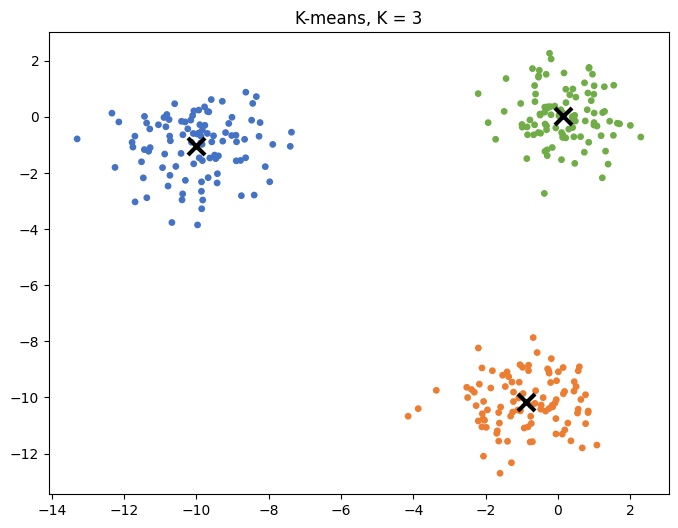

Инерция: 600.1
Итераций до сходимости: 2


In [4]:
km = KMeans(n_clusters=3, n_init=10, random_state=42)
labels = km.fit_predict(X)   # fit + predict в одном вызове; то же лежит в km.labels_

plot_clusters(X, labels, centers=km.cluster_centers_, title='K-means, K = 3')
plt.show()
print('Инерция:', round(km.inertia_, 1))
print('Итераций до сходимости:', km.n_iter_)

Облака хорошо разделены, и K-means находит их без ошибок. Центры (крестики) стоят в середине облаков.

### 1.2 Что если не угадать число кластеров

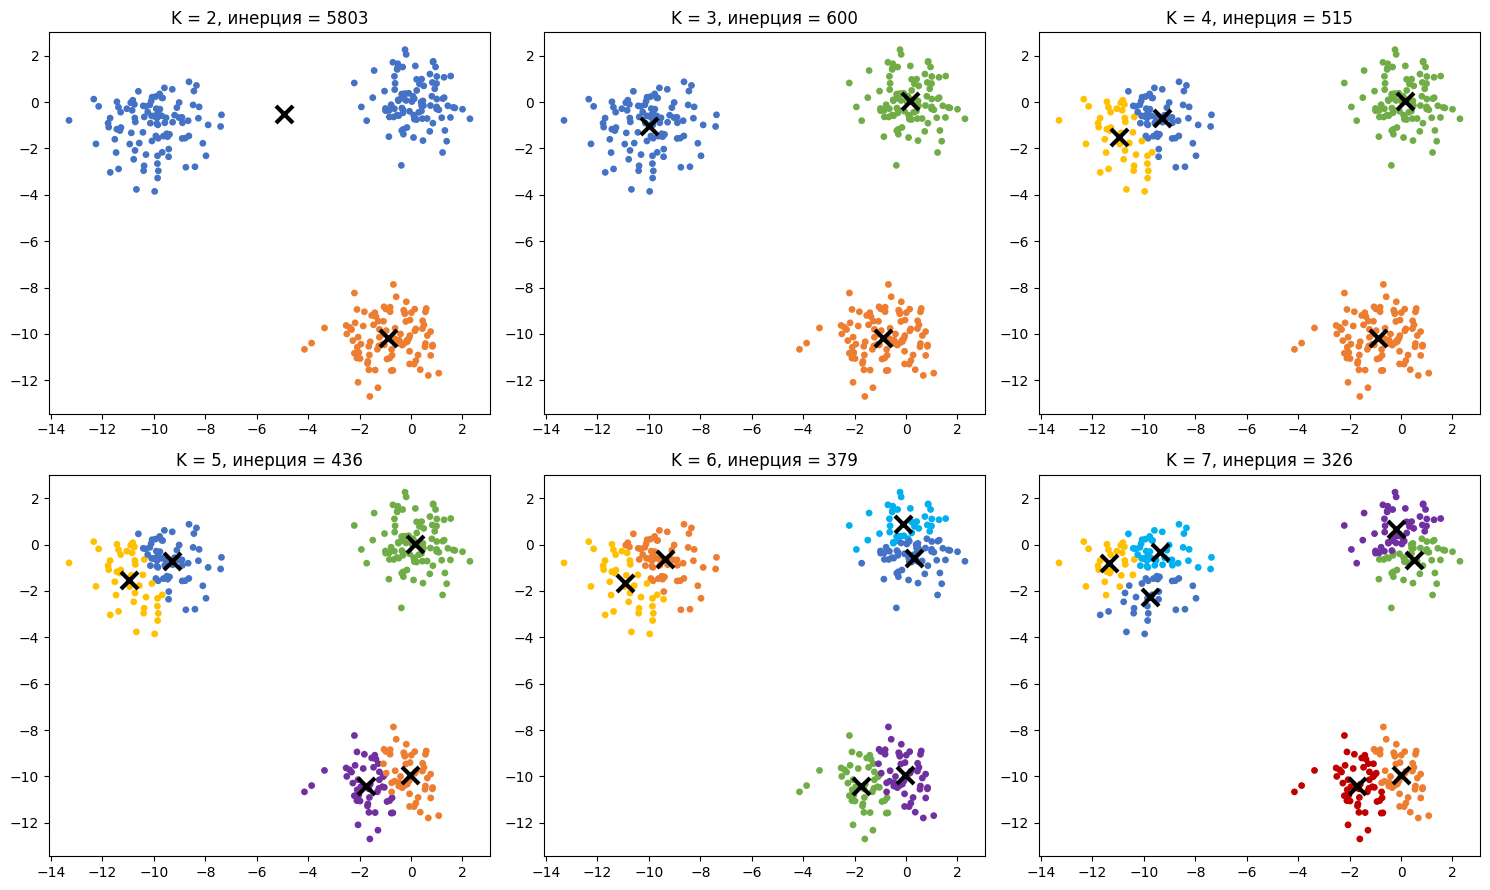

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, k in zip(axes.ravel(), range(2, 8)):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    plot_clusters(X, km_k.labels_, ax=ax, centers=km_k.cluster_centers_,
                  title=f'K = {k}, инерция = {km_k.inertia_:.0f}')
plt.tight_layout()
plt.show()

**Что мы видим.** При $K = 2$ два облака сливаются в один кластер. При $K > 3$ K-means режет настоящие облака на части: каждый центр обязан получить свои точки. Инерция при этом продолжает уменьшаться.

**Вопрос.** Почему инерция падает при каждом увеличении $K$, хотя кластеров на самом деле три? Можно ли выбрать $K$ по минимуму инерции?

<details>
<summary><b>Показать ответ</b></summary>

Новый центр всегда можно поставить так, чтобы часть точек оказалась к нему ближе, поэтому сумма квадратов расстояний не растёт с ростом $K$. В пределе при $K = n$ каждая точка — свой центр, и инерция равна нулю. Значит, минимум инерции ничего не говорит о числе кластеров. Смотрят на то, где падение резко замедляется (правило локтя), или на метрики, которые не улучшаются автоматически с ростом $K$, например силуэт.

</details>

### 1.3 Инициализация

K-means находит только **локальный** минимум инерции: результат зависит от стартовых центров. Возьмём четыре облака и запустим алгоритм со случайной инициализацией (`init='random'`) по одному разу (`n_init=1`) с разными `random_state`.

In [6]:
X4, y4 = make_blobs(n_samples=400, centers=[[0, 0], [0, 6], [7, 0], [7, 6]],
                    cluster_std=0.9, random_state=3)

rows = []
for seed in range(10):
    m = KMeans(n_clusters=4, init='random', n_init=1, random_state=seed).fit(X4)
    rows.append({'random_state': seed, 'инерция': round(m.inertia_, 1)})
pd.DataFrame(rows).set_index('random_state').T

random_state,0,1,2,3,4,5,6,7,8,9
инерция,649.4,649.4,649.4,649.4,2500.2,649.4,2503.9,2399.1,2385.2,649.4


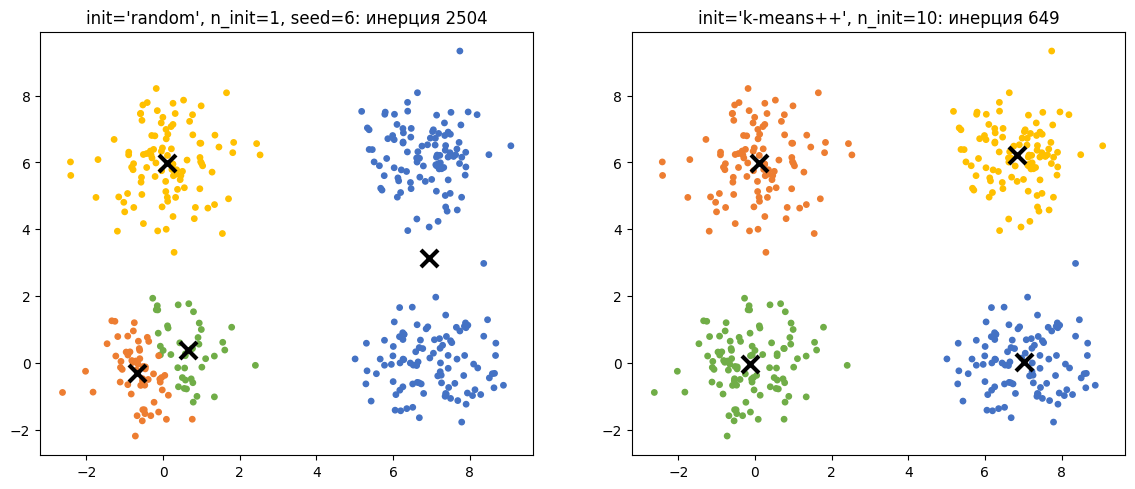

In [7]:
bad_seed = max(rows, key=lambda r: r['инерция'])['random_state']
m_bad = KMeans(n_clusters=4, init='random', n_init=1, random_state=bad_seed).fit(X4)
m_good = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42).fit(X4)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_clusters(X4, m_bad.labels_, ax=axes[0], centers=m_bad.cluster_centers_,
              title=f"init='random', n_init=1, seed={bad_seed}: инерция {m_bad.inertia_:.0f}")
plot_clusters(X4, m_good.labels_, ax=axes[1], centers=m_good.cluster_centers_,
              title=f"init='k-means++', n_init=10: инерция {m_good.inertia_:.0f}")
plt.show()

**Вопрос.** Почему неудачный запуск не исправляется сам за следующие итерации? Что делают параметры `init='k-means++'` и `n_init`?

<details>
<summary><b>Показать ответ</b></summary>

Каждая итерация K-means не увеличивает инерцию, поэтому алгоритм «скатывается» в ближайший локальный минимум и там останавливается. Если два центра попали в одно облако, а один центр стоит между двумя другими облаками, то ни один шаг не перетянет центр через пустое пространство: точки облаков ближе к «своему» неудачному центру.

`k-means++` выбирает стартовые центры подальше друг от друга: каждый следующий берётся с вероятностью, пропорциональной квадрату расстояния до ближайшего уже выбранного. `n_init` запускает алгоритм несколько раз с разных стартов и оставляет решение с наименьшей инерцией. Вместе они почти всегда находят хорошее решение.

</details>

[Интерактивная визуализация K-means](https://www.naftaliharris.com/blog/visualizing-k-means-clustering/)

## 2. Качество кластеризации

На лекции метрики делились на две группы:

- **внешние** используют истинные метки: ARI ([adjusted_rand_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html)), гомогенность, полнота и V-мера ([v_measure_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.v_measure_score.html));
- **внутренние** смотрят только на данные: силуэт ([silhouette_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)), инерция.

В реальной задаче истинных меток нет. Здесь они есть, потому что данные сгенерированы, и можно проверить, насколько внутренние метрики согласуются с внешними.

### 2.1 Метрики для K = 3

In [8]:
def all_metrics(X, y_true, labels):
    return {'силуэт': silhouette_score(X, labels),
            'ARI': adjusted_rand_score(y_true, labels),
            'гомогенность': homogeneity_score(y_true, labels),
            'полнота': completeness_score(y_true, labels),
            'V-мера': v_measure_score(y_true, labels)}

labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
pd.Series(all_metrics(X, y, labels)).round(3)

,0
силуэт,0.823
ARI,1.000
гомогенность,1.000
полнота,1.000
V-мера,1.000


Все внешние метрики равны 1: разбиение совпадает с истинным с точностью до перестановки номеров (номера кластеров условные, метрики это учитывают).

### 2.2 Подбор числа кластеров

In [9]:
ks = range(2, 9)
rows = []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    rows.append({'K': k, 'инерция': m.inertia_, **all_metrics(X, y, m.labels_)})
scores = pd.DataFrame(rows).set_index('K')
scores.round(3)

,инерция,силуэт,ARI,гомогенность,полнота,V-мера
K,,,,,,
2,5803.288,0.597,0.570,0.579,1.000,0.734
3,600.109,0.823,1.000,1.000,1.000,1.000
4,515.267,0.661,0.872,1.000,0.829,0.906
5,436.316,0.502,0.729,1.000,0.706,0.828
6,379.484,0.334,0.581,1.000,0.618,0.764
7,326.256,0.339,0.517,1.000,0.573,0.728
8,289.380,0.336,0.471,1.000,0.538,0.700


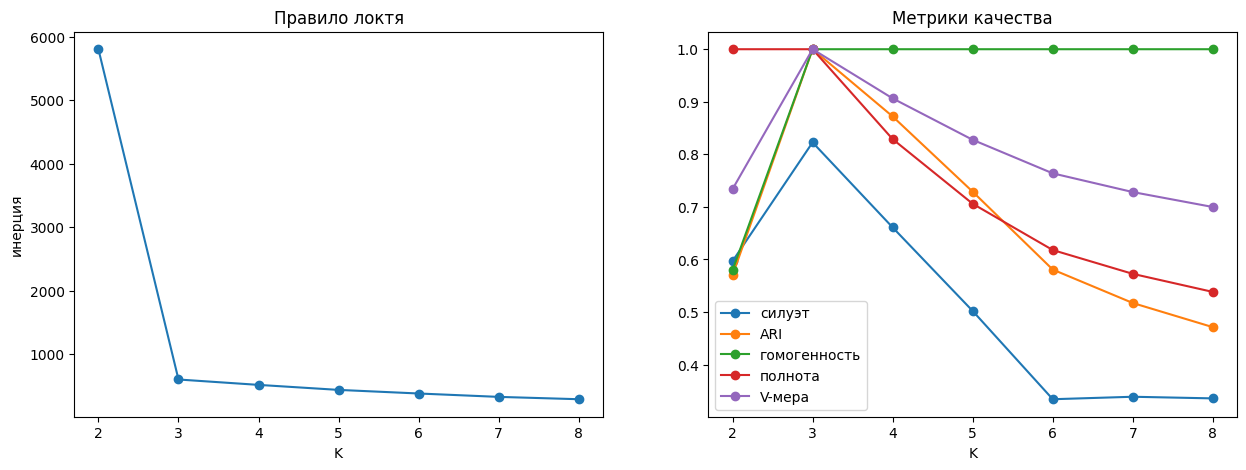

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(scores.index, scores['инерция'], 'o-')
axes[0].set_xlabel('K'); axes[0].set_ylabel('инерция'); axes[0].set_title('Правило локтя')
for col in ['силуэт', 'ARI', 'гомогенность', 'полнота', 'V-мера']:
    axes[1].plot(scores.index, scores[col], 'o-', label=col)
axes[1].set_xlabel('K'); axes[1].set_title('Метрики качества'); axes[1].legend()
plt.show()

**Что мы видим.** Инерция резко падает до $K = 3$ и дальше почти не меняется: это «локоть». Силуэт, ARI, полнота и V-мера достигают максимума при $K = 3$. Гомогенность ведёт себя иначе.

**Вопрос.** Почему гомогенность при $K > 3$ остаётся равной 1, а полнота падает? Почему поэтому нельзя выбирать $K$ по одной гомогенности?

<details>
<summary><b>Показать ответ</b></summary>

Гомогенность проверяет, что каждый кластер содержит объекты только одного класса. При $K > 3$ K-means режет облака на части, и каждая часть по-прежнему «чистая», поэтому гомогенность остаётся 1. Предельный случай — каждый объект в своём кластере, гомогенность тоже 1.

Полнота проверяет обратное: все объекты одного класса лежат в одном кластере. Когда облако разрезано, это нарушается, и полнота падает. Гомогенность и полнота тянут в разные стороны, как точность и полнота в классификации, поэтому смотрят на V-меру (их среднее гармоническое) или на ARI.

</details>

### 2.3 Масштабирование признаков

K-means, DBSCAN и иерархическая кластеризация считают расстояния между объектами. Если признаки измерены в разных шкалах, расстояние определяет признак с самым большим разбросом. Проверим на датасете [Wine](https://scikit-learn.org/stable/datasets/toy_dataset.html#wine-recognition-dataset): 178 вин трёх сортов, 13 химических признаков. Сорт известен, поэтому качество можно проверить по ARI.

In [11]:
wine = load_wine(as_frame=True)
Xw, yw = wine.data, wine.target
Xw.describe().loc[['mean', 'std', 'min', 'max']].round(2).T.sort_values('std', ascending=False).head(6)

,mean,std,min,max
proline,746.89,314.91,278.00,1680.00
magnesium,99.74,14.28,70.00,162.00
alcalinity_of_ash,19.49,3.34,10.60,30.00
color_intensity,5.06,2.32,1.28,13.00
malic_acid,2.34,1.12,0.74,5.80
flavanoids,2.03,1.00,0.34,5.08


In [12]:
labels_raw = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Xw)
Xw_scaled = StandardScaler().fit_transform(Xw)
labels_scaled = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(Xw_scaled)

pd.DataFrame({'без масштабирования': {'ARI': adjusted_rand_score(yw, labels_raw),
                                      'силуэт': silhouette_score(Xw, labels_raw)},
              'StandardScaler': {'ARI': adjusted_rand_score(yw, labels_scaled),
                                 'силуэт': silhouette_score(Xw_scaled, labels_scaled)}}).round(3)

,без масштабирования,StandardScaler
ARI,0.371,0.897
силуэт,0.571,0.285


In [13]:
pd.crosstab(yw, labels_raw, rownames=['сорт'], colnames=['кластер (без масштабирования)'])

кластер (без масштабирования),0,1,2
сорт,,,
0,13,46,0
1,20,1,50
2,29,0,19


In [14]:
pd.crosstab(yw, labels_scaled, rownames=['сорт'], colnames=['кластер (StandardScaler)'])

кластер (StandardScaler),0,1,2
сорт,,,
0,0,0,59
1,65,3,3
2,0,48,0


**Вопрос.** Почему без масштабирования K-means плохо восстанавливает сорта? И почему силуэт без масштабирования выше, хотя разбиение хуже?

<details>
<summary><b>Показать ответ</b></summary>

У признака `proline` стандартное отклонение около 315, у `magnesium` около 14, у остальных — единицы и доли единицы. Квадрат евклидова расстояния почти целиком определяется разницей в `proline`, и K-means фактически кластеризует вина по одному признаку. Из таблиц сопряжённости видно: в кластер 0 попали вина всех трёх сортов, а сорта 1 и 2 перемешаны между кластерами; ARI всего 0,371. После стандартизации все признаки вносят сопоставимый вклад, ARI вырастает до 0,897, ошибок остаётся 6 из 178.

Силуэт без масштабирования выше (0,571 против 0,285), потому что он считается в том же пространстве, в котором шла кластеризация. Без масштабирования данные почти одномерны (вдоль `proline`), а разрезать одну ось на три отрезка можно очень «чисто». Силуэты в разных пространствах признаков сравнивать нельзя: метрика оценивает геометрию данных, а не то, совпадают ли кластеры с осмысленными группами.

</details>

## 3. DBSCAN

DBSCAN ищет области высокой плотности. У алгоритма два гиперпараметра:

1. `eps` ($\varepsilon$) — радиус окрестности;
2. `min_samples` ($N_0$) — сколько точек должно быть в $\varepsilon$-окрестности, **включая саму точку**, чтобы точка считалась основной.

Типы точек:

- **основная** (core): в её $\varepsilon$-окрестности не менее `min_samples` точек;
- **граничная** (border): сама не основная, но лежит в окрестности какой-то основной точки;
- **шумовая** (noise): не основная и не попадает в окрестность ни одной основной точки. В `sklearn` получает метку $-1$.

Кластер образуют основные точки, которые лежат в окрестностях друг друга (цепочкой), вместе со своими граничными точками. Граничные точки не продолжают цепочку: через них кластер дальше не растёт.

Рассмотрим диаграмму для `min_samples = 4`. Точка $A$ и другие красные точки основные: в круге радиуса `eps` вокруг каждой не меньше 4 точек, включая саму точку. Они достижимы друг из друга и образуют один кластер. Точки $B$ и $C$ не основные, но лежат в окрестности основных точек — это граничные точки того же кластера. Точка $N$ — шум.

### 3.1 Влияние `eps` и `min_samples`

Вернёмся к трём облакам из раздела 1. Строки — `min_samples`, столбцы — `eps`, серые точки — шум.

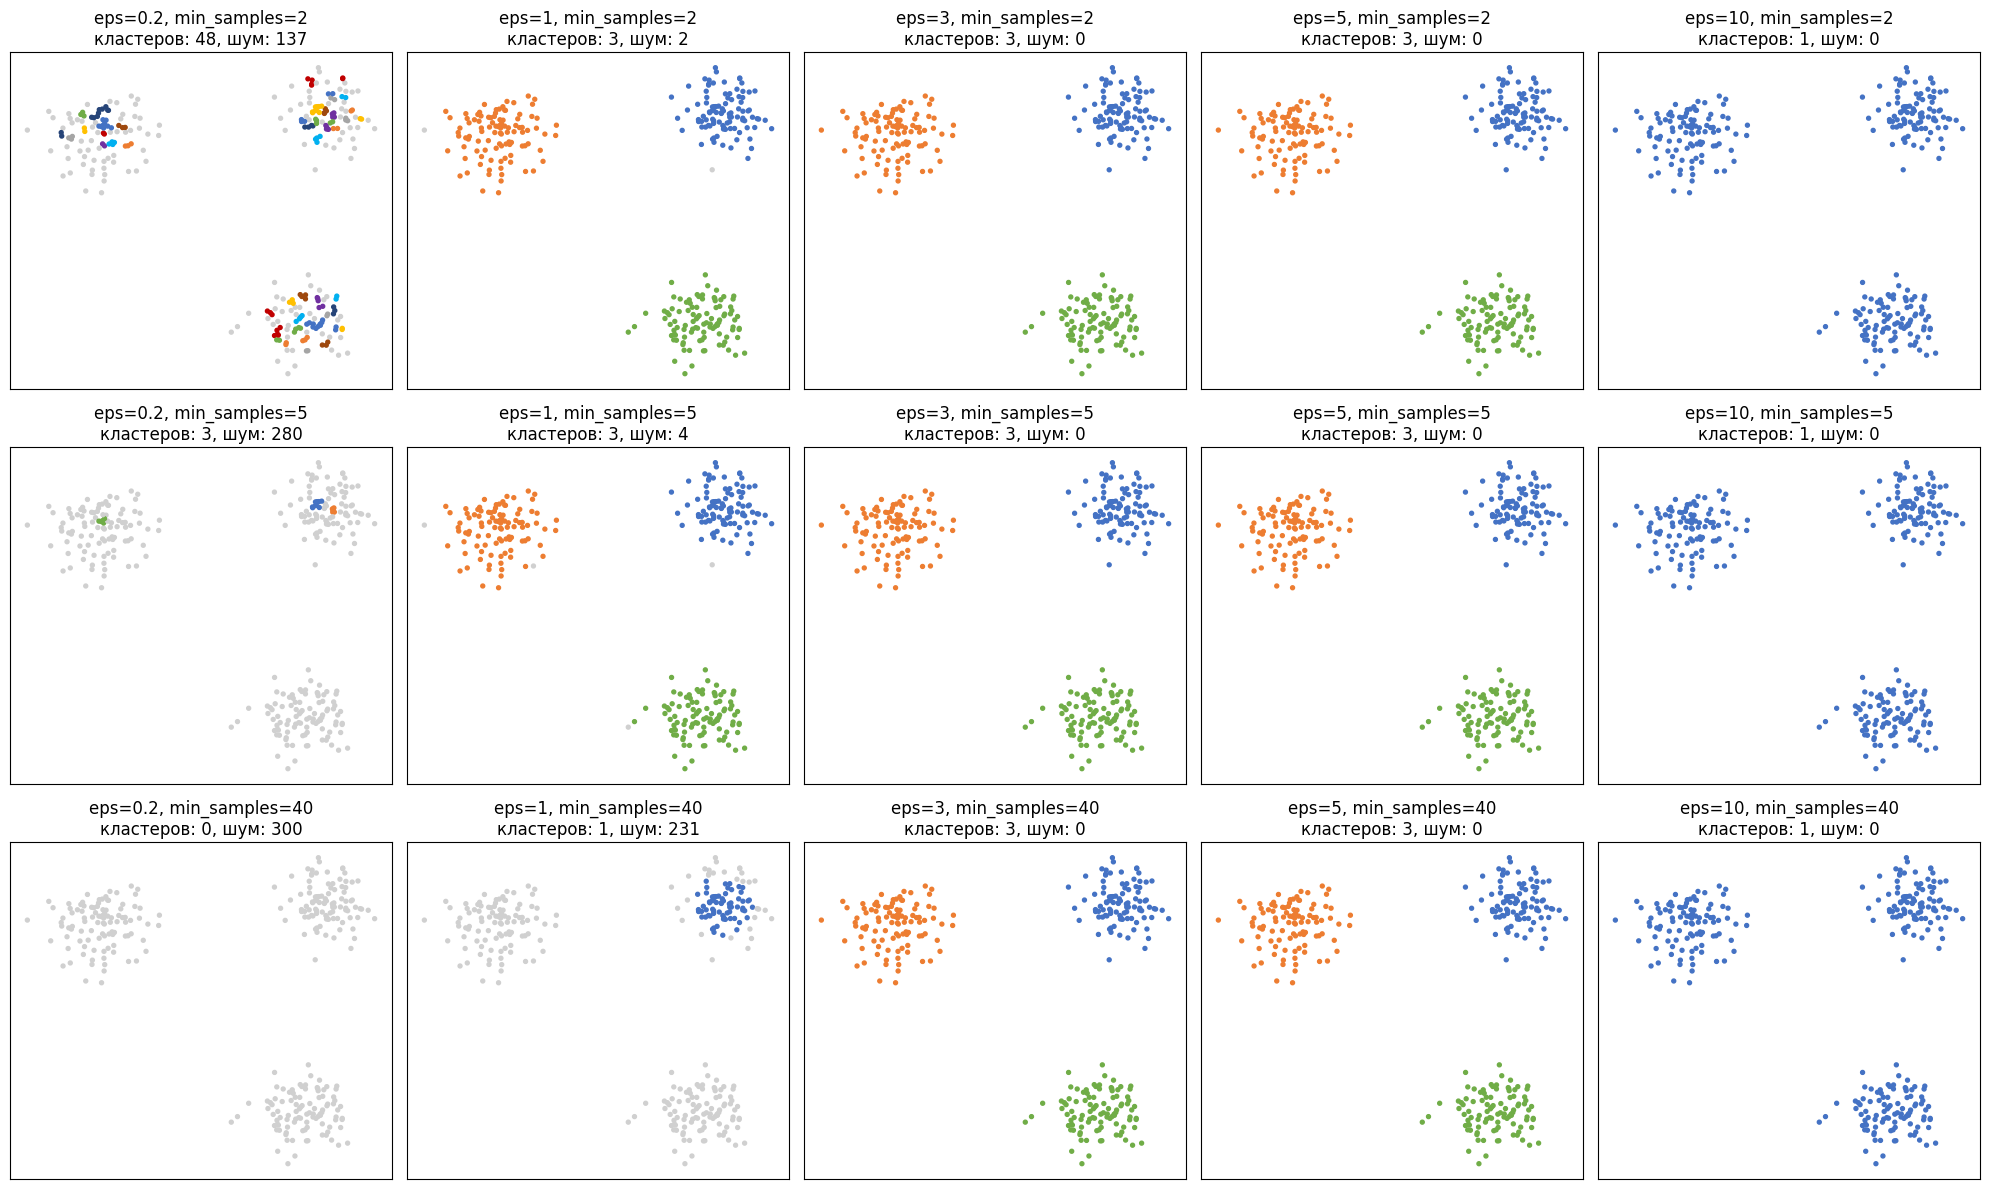

In [15]:
eps_list = [0.2, 1, 3, 5, 10]
ms_list = [2, 5, 40]

fig, axes = plt.subplots(len(ms_list), len(eps_list), figsize=(20, 12))
for i, ms in enumerate(ms_list):
    for j, e in enumerate(eps_list):
        lab = DBSCAN(eps=e, min_samples=ms).fit_predict(X)
        n_cl = lab.max() + 1
        n_noise = (lab == -1).sum()
        plot_clusters(X, lab, ax=axes[i, j], s=8,
                      title=f'eps={e}, min_samples={ms}\nкластеров: {n_cl}, шум: {n_noise}')
        axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
plt.tight_layout()
plt.show()

**Что мы видим.** При маленьком `eps` почти все точки — шум или крошечные кластеры. При `eps` порядка 1–3 находятся три облака. При большом `eps` облака сливаются. Чем больше `min_samples`, тем строже требование к плотности: шума становится больше.

**Вопрос.** Что произойдёт с DBSCAN при $\varepsilon \to 0$ и при $\varepsilon \to \infty$ (при фиксированном `min_samples > 1`)?

<details>
<summary><b>Показать ответ</b></summary>

При $\varepsilon \to 0$ в окрестности каждой точки остаётся только она сама, основных точек нет, и **все** точки объявляются шумом (метка $-1$).

При $\varepsilon \to \infty$ в окрестность каждой точки попадает вся выборка, все точки основные и достижимы друг из друга, поэтому получается **один** кластер без шума. Полезные значения лежат между этими крайностями, и их нужно подбирать под масштаб данных (поэтому признаки тоже стоит масштабировать).

</details>

### 3.2 Выбор `eps` по графику k-расстояний

Чтобы не подбирать `eps` наугад, для каждой точки считают расстояние до `min_samples`-го ближайшего соседа (сама точка считается первым) и сортируют эти расстояния. Внутри кластеров они маленькие, у шумовых точек большие. `eps` берут в районе «излома», где кривая начинает резко расти.

Возьмём «полумесяцы»: на них хорошо видно разницу между K-means и DBSCAN.

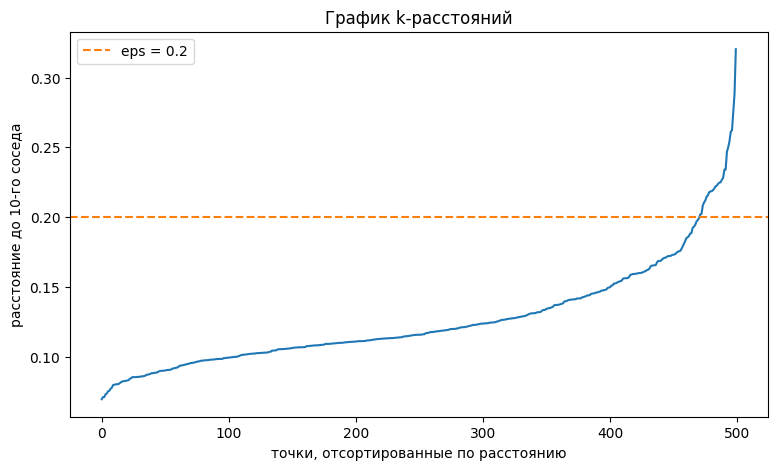

In [16]:
X_moons, y_moons = make_moons(n_samples=500, noise=0.1, random_state=42)

min_samples = 10
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_moons)
dist, _ = nn.kneighbors(X_moons)          # dist[:, 0] = 0 — это сама точка
k_dist = np.sort(dist[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_dist)
plt.axhline(0.2, color='C1', ls='--', label='eps = 0.2')
plt.xlabel('точки, отсортированные по расстоянию')
plt.ylabel(f'расстояние до {min_samples}-го соседа')
plt.legend(); plt.title('График k-расстояний')
plt.show()

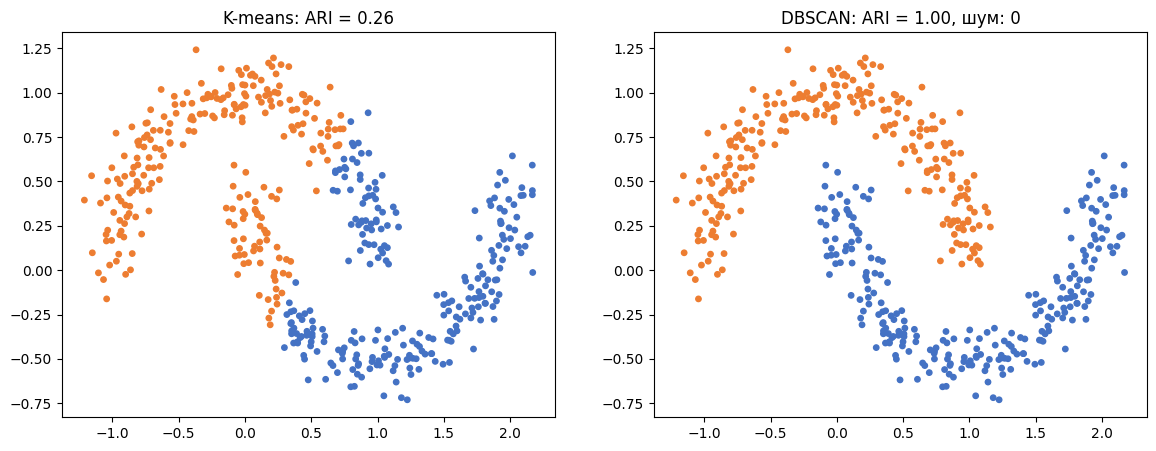

In [17]:
labels_km = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_moons)
labels_db = DBSCAN(eps=0.2, min_samples=min_samples).fit_predict(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_clusters(X_moons, labels_km, ax=axes[0], title=f'K-means: ARI = {adjusted_rand_score(y_moons, labels_km):.2f}')
plot_clusters(X_moons, labels_db, ax=axes[1],
              title=f'DBSCAN: ARI = {adjusted_rand_score(y_moons, labels_db):.2f}, шум: {(labels_db == -1).sum()}')
plt.show()

Теперь концентрические окружности.

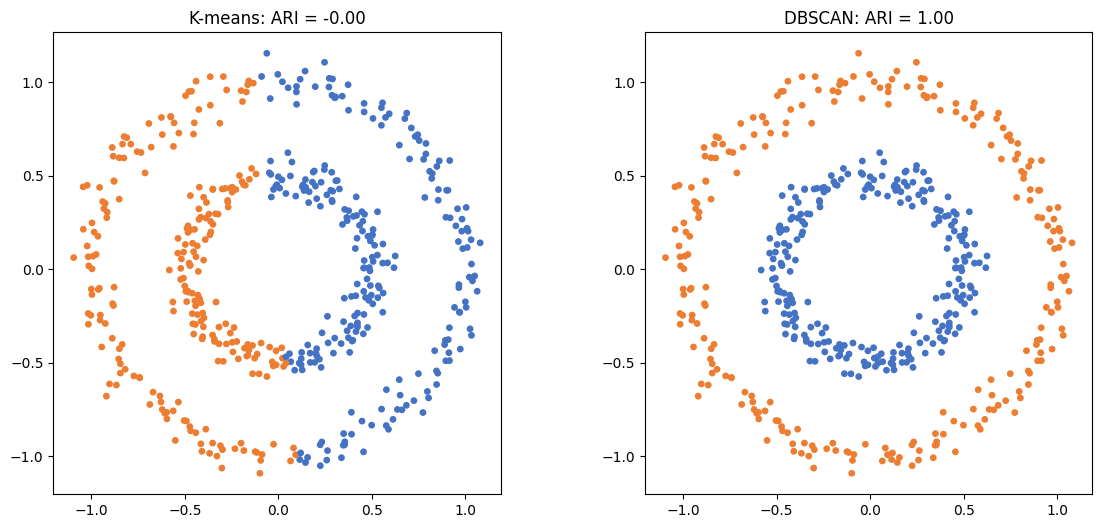

In [18]:
X_circ, y_circ = make_circles(n_samples=500, noise=0.05, factor=0.5, random_state=42)

labels_km = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_circ)
labels_db = DBSCAN(eps=0.2, min_samples=10).fit_predict(X_circ)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_clusters(X_circ, labels_km, ax=axes[0], title=f'K-means: ARI = {adjusted_rand_score(y_circ, labels_km):.2f}')
plot_clusters(X_circ, labels_db, ax=axes[1], title=f'DBSCAN: ARI = {adjusted_rand_score(y_circ, labels_db):.2f}')
for ax in axes: ax.set_aspect('equal')
plt.show()

**Вопрос.** Почему K-means не может разделить две окружности, сколько бы раз его ни перезапускали?

<details>
<summary><b>Показать ответ</b></summary>

K-means относит точку к ближайшему центру. Граница между двумя кластерами — множество точек, равноудалённых от двух центров, то есть прямая (в общем случае гиперплоскость). Поэтому кластеры K-means всегда выпуклые: области Вороного вокруг центров. Внешнее кольцо охватывает внутреннее, и никакая прямая их не разделит. Кроме того, центры обоих колец совпадают, и «середина» внешнего кольца лежит в пустоте. DBSCAN не опирается на центры: он соединяет точки по цепочкам плотных окрестностей, поэтому может найти кластер любой формы.

</details>

[Интерактивная визуализация DBSCAN](https://www.naftaliharris.com/blog/visualizing-dbscan-clustering/)

## 4. Иерархическая кластеризация

Иерархический подход строит не одно разбиение, а целое дерево разбиений. Есть два варианта:

1. **агломеративный**: на каждой итерации два ближайших кластера объединяются в один;
2. **дивизивный**: на каждой итерации один кластер делится на два.

Рассмотрим агломеративный (он используется чаще и реализован в `sklearn`):

- сначала каждая точка — отдельный кластер, для выборки из $N$ точек это $N$ кластеров;
- на каждом шаге объединяем два кластера, расстояние между которыми минимально;
- повторяем, пока все точки не окажутся в одном кластере.

Результат зависит от того, как считать **расстояние между кластерами** $U$ и $V$ (параметр `linkage`):

- `single` — минимальное расстояние между их точками;
- `complete` — максимальное;
- `average` — среднее по всем парам;
- `ward` (по умолчанию) — насколько вырастет сумма квадратов расстояний до центра, если кластеры объединить:

$$
\Delta = \sum_{x_i \in U \cup V} \lVert x_i - \bar{x} \rVert^2 - \sum_{x_i \in U} \lVert x_i - \bar{u} \rVert^2 - \sum_{x_i \in V} \lVert x_i - \bar{v} \rVert^2 ,
$$

где $\bar{u}$, $\bar{v}$, $\bar{x}$ — центры кластеров $U$, $V$ и их объединения. Уорд, как и K-means, минимизирует внутрикластерную сумму квадратов.

Историю объединений изображают **дендрограммой**: высота горизонтальной перемычки — расстояние, на котором объединились два кластера. Число кластеров выбирают уже после построения дерева, «разрезав» его на нужной высоте.

### 4.1 Дендрограмма и разрез

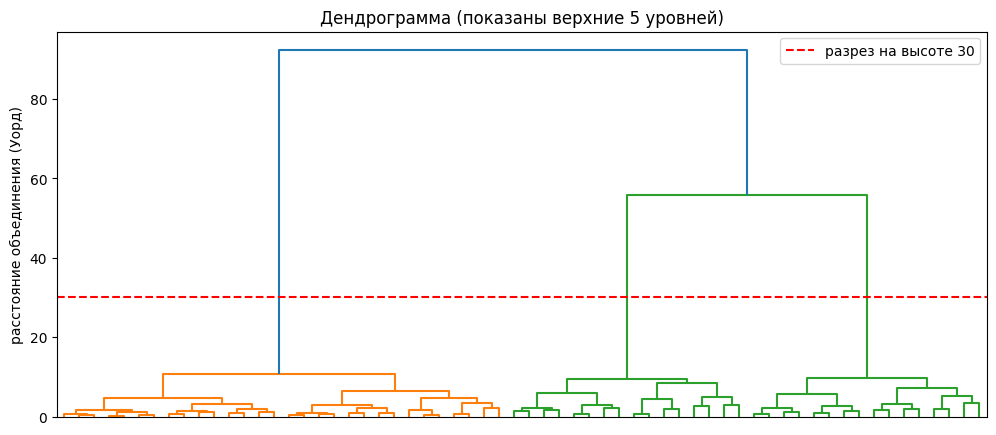

In [19]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

X_bl, y_bl = make_blobs(n_samples=200, random_state=170)

Z = linkage(X_bl, method='ward')   # матрица объединений: кто с кем и на какой высоте

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='level', p=5, no_labels=True)
plt.axhline(30, color='red', ls='--', label='разрез на высоте 30')
plt.ylabel('расстояние объединения (Уорд)')
plt.title('Дендрограмма (показаны верхние 5 уровней)')
plt.legend()
plt.show()

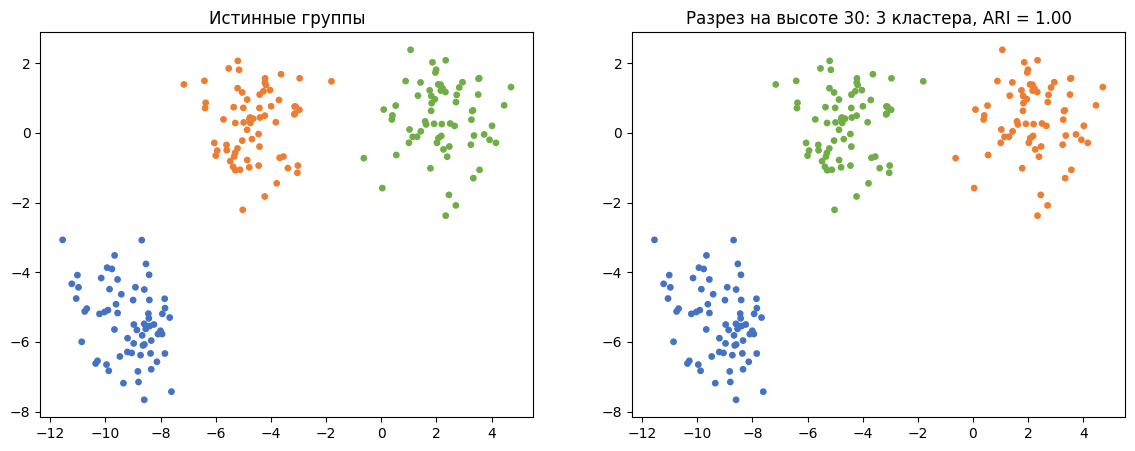

In [20]:
labels_h = fcluster(Z, t=30, criterion='distance') - 1   # номера кластеров с 0

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_clusters(X_bl, y_bl, ax=axes[0], title='Истинные группы')
plot_clusters(X_bl, labels_h, ax=axes[1],
              title=f'Разрез на высоте 30: {labels_h.max() + 1} кластера, ARI = {adjusted_rand_score(y_bl, labels_h):.2f}')
plt.show()

Тот же результат даёт `AgglomerativeClustering(n_clusters=3, linkage='ward')` из `sklearn`: задать число кластеров или порог расстояния (`distance_threshold`) — два способа разрезать одно и то же дерево.

In [21]:
labels_sk = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_bl)
print('ARI между scipy и sklearn:', adjusted_rand_score(labels_h, labels_sk))

ARI между scipy и sklearn: 1.0


**Вопрос.** Как по дендрограмме выбрать число кластеров?

<details>
<summary><b>Показать ответ</b></summary>

Ищут самый большой вертикальный промежуток, в котором не происходит объединений, и режут дерево внутри него. Здесь три нижних слияния верхнего уровня происходят на высотах около 9–11, затем два кластера объединяются на высоте 55,7 и последние два — на 92,3. Самый длинный «пустой» промежуток — от 10,8 до 55,7, разрез в нём (например, на высоте 30) даёт 3 кластера. Разрез между 55,7 и 92,3 дал бы 2 кластера, но этот промежуток короче.

Это эвристика, а не правило: если из предметной области известно, сколько групп нужно (например, не больше пяти сегментов клиентов), дерево режут под это число.

</details>

### 4.2 Способ связи и форма кластеров

Сгенерируем зашумлённую спираль и сравним способы связи. Во второй строке добавим ограничение связности (`connectivity`): объединять можно только кластеры, точки которых соседствуют в графе 30 ближайших соседей.

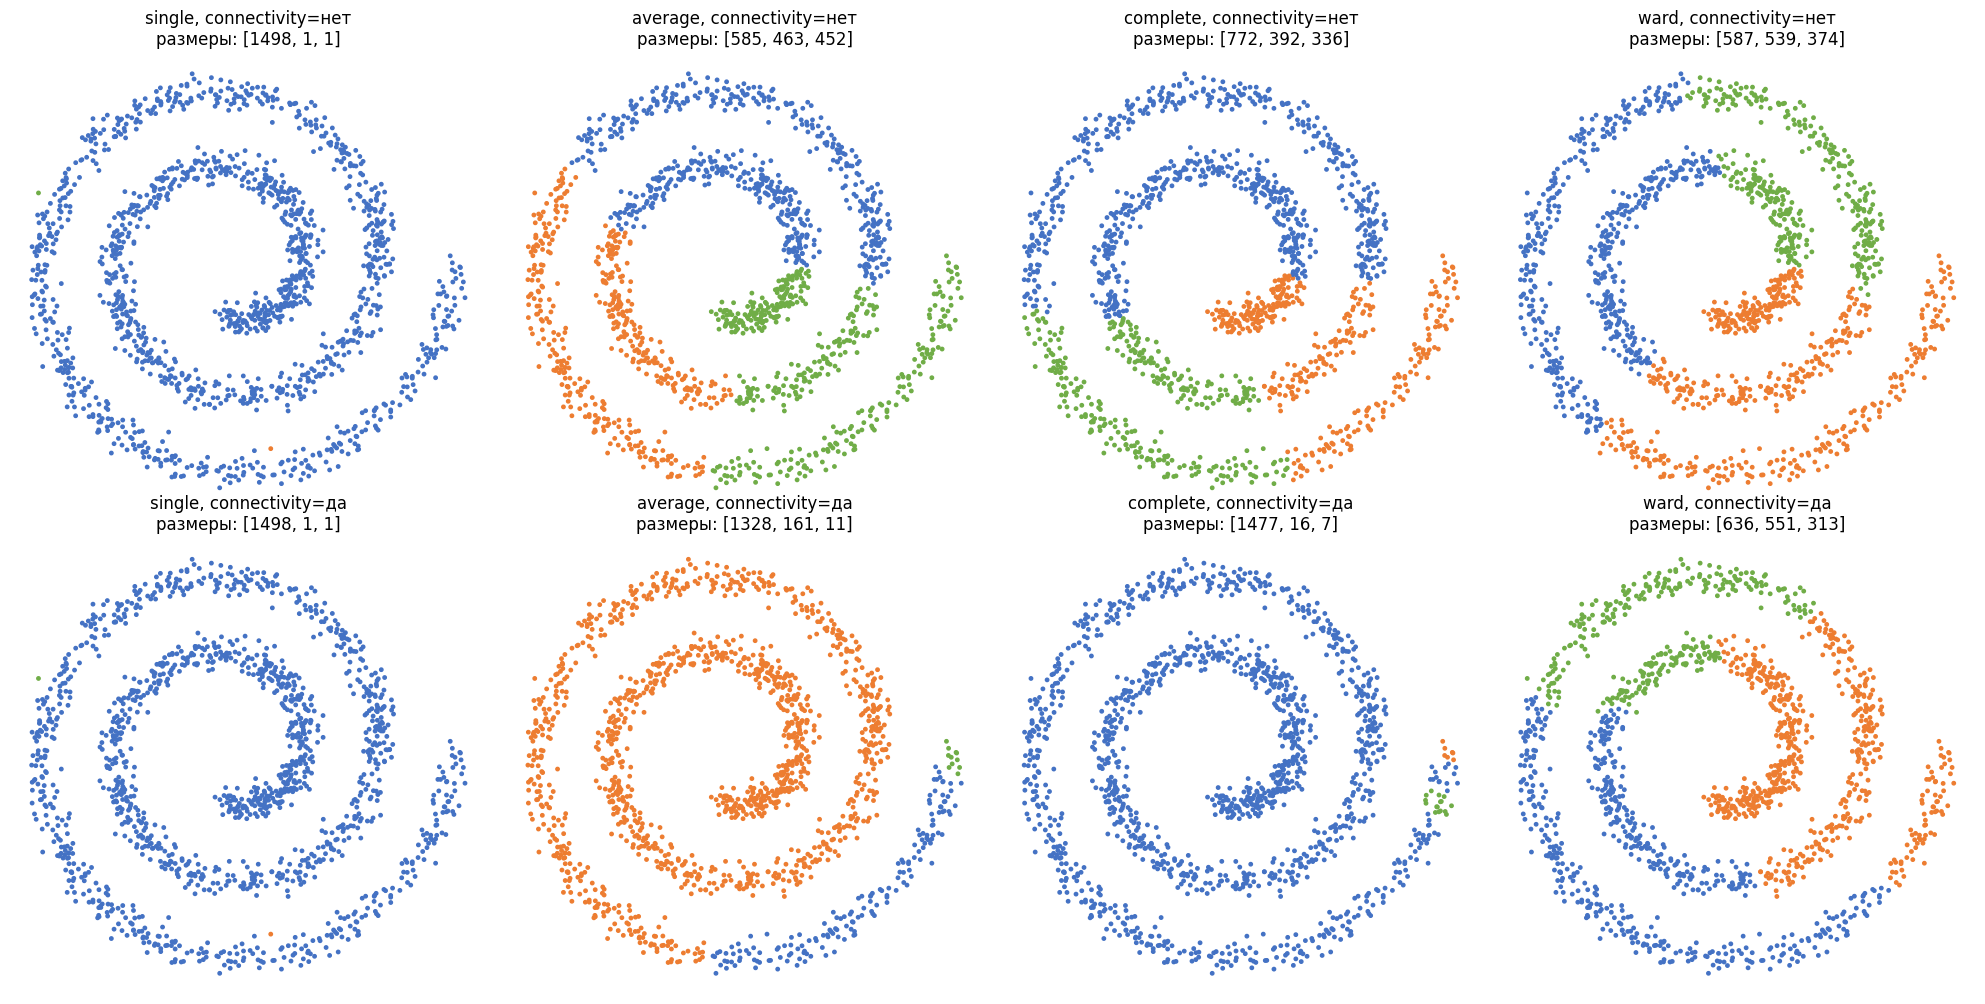

In [22]:
from sklearn.neighbors import kneighbors_graph

rng = np.random.default_rng(0)
n = 1500
t = 1.5 * np.pi * (1 + 3 * rng.random(n))
X_sp = np.column_stack((t * np.cos(t), t * np.sin(t))) + 0.7 * rng.normal(size=(n, 2))

knn_graph = kneighbors_graph(X_sp, 30, include_self=False)

linkages = ['single', 'average', 'complete', 'ward']
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for row, conn in enumerate([None, knn_graph]):
    for col, link in enumerate(linkages):
        lab = AgglomerativeClustering(n_clusters=3, linkage=link, connectivity=conn).fit_predict(X_sp)
        sizes = np.bincount(lab)
        plot_clusters(X_sp, lab, ax=axes[row, col], s=6,
                      title=f"{link}, connectivity={'да' if conn is not None else 'нет'}\nразмеры: {sorted(sizes.tolist(), reverse=True)}")
        axes[row, col].set_aspect('equal'); axes[row, col].axis('off')
plt.tight_layout()
plt.show()

**Что мы видим.** Спираль — одна непрерывная кривая, поэтому «правильного» разбиения на 3 кластера здесь нет: пример показывает, как способ связи определяет форму кластеров.

- `single` без ограничения связности: кластеры размером 1498, 1 и 1 — почти всё в одном кластере, плюс две отдельные точки.
- `average`, `complete` и `ward` без ограничения режут спираль на куски, которые захватывают части соседних витков.
- С ограничением связности кластеры следуют вдоль кривой: у `ward` это три сопоставимых участка спирали (636, 551, 313 точек), а `average` и `complete` дают один большой кластер и пару маленьких.

**Вопрос.** Почему `single` без ограничения связности даёт один огромный кластер и пару крошечных, а `ward` режет спираль поперёк витков?

<details>
<summary><b>Показать ответ</b></summary>

`single` объединяет кластеры по **ближайшей** паре точек. Шум заполняет промежутки между витками, и по цепочке близких точек все витки быстро сливаются в один кластер (эффект цепочки). Дольше всего остаются отдельными несколько точек, далёких от всех остальных. Поэтому разрез на 3 кластера отделяет две одиночные точки от всей спирали.

`ward` объединяет кластеры так, чтобы внутрикластерная сумма квадратов росла как можно меньше, то есть, как и K-means, ищет компактные «шарообразные» группы. Он не знает про форму кривой и режет плоскость на области, захватывая куски соседних витков. Ограничение связности запрещает объединять кластеры, точки которых не соседствуют в графе ближайших соседей, поэтому кластеры вынуждены идти вдоль спирали.

</details>

## 5. HDBSCAN

У DBSCAN один `eps` на всю выборку. Если кластеры разной плотности, подходящего значения может не существовать: для плотного кластера `eps` должен быть маленьким, для разреженного — большим.

HDBSCAN перебирает все значения `eps` сразу:

1. для каждой точки считает расстояние до `min_samples`-го соседа (мера локальной плотности) и с его учётом пересчитывает расстояния между точками;
2. строит по этим расстояниям иерархию кластеров, как в иерархической кластеризации;
3. оставляет самые **устойчивые** кластеры — те, что существуют в широком диапазоне `eps`.

Главный гиперпараметр — `min_cluster_size`: кластеры меньше этого размера считаются шумом. В `sklearn` HDBSCAN доступен как `sklearn.cluster.HDBSCAN` (с версии 1.3), отдельный пакет `hdbscan` не нужен.

In [23]:
X_var, y_var = make_blobs(n_samples=[150, 150, 150], centers=[[0, 0], [1.2, 0], [6, 4]],
                          cluster_std=[0.2, 0.2, 1.3], random_state=42)
noise = np.random.default_rng(42).uniform([-3, -3], [11, 9], size=(60, 2))
X_var = np.vstack([X_var, noise])
y_var = np.concatenate([y_var, -np.ones(60, dtype=int)])   # шум помечаем -1

# Как ведёт себя DBSCAN при разных eps
rows = []
for e in [0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0]:
    lab = DBSCAN(eps=e, min_samples=5).fit_predict(X_var)
    rows.append({'eps': e,
                 'кластеров': lab.max() + 1,
                 'доля шума в разреженном облаке': (lab[y_var == 2] == -1).mean(),
                 'плотные облака слились': bool(set(lab[y_var == 0]) & set(lab[y_var == 1]) - {-1})})
pd.DataFrame(rows).set_index('eps').round(2)

,кластеров,доля шума в разреженном облаке,плотные облака слились
eps,,,
0.15,3,0.97,False
0.20,3,0.95,False
0.30,8,0.71,False
0.40,5,0.40,True
0.50,5,0.16,True
0.60,3,0.07,True
0.80,3,0.03,True
1.00,2,0.02,True


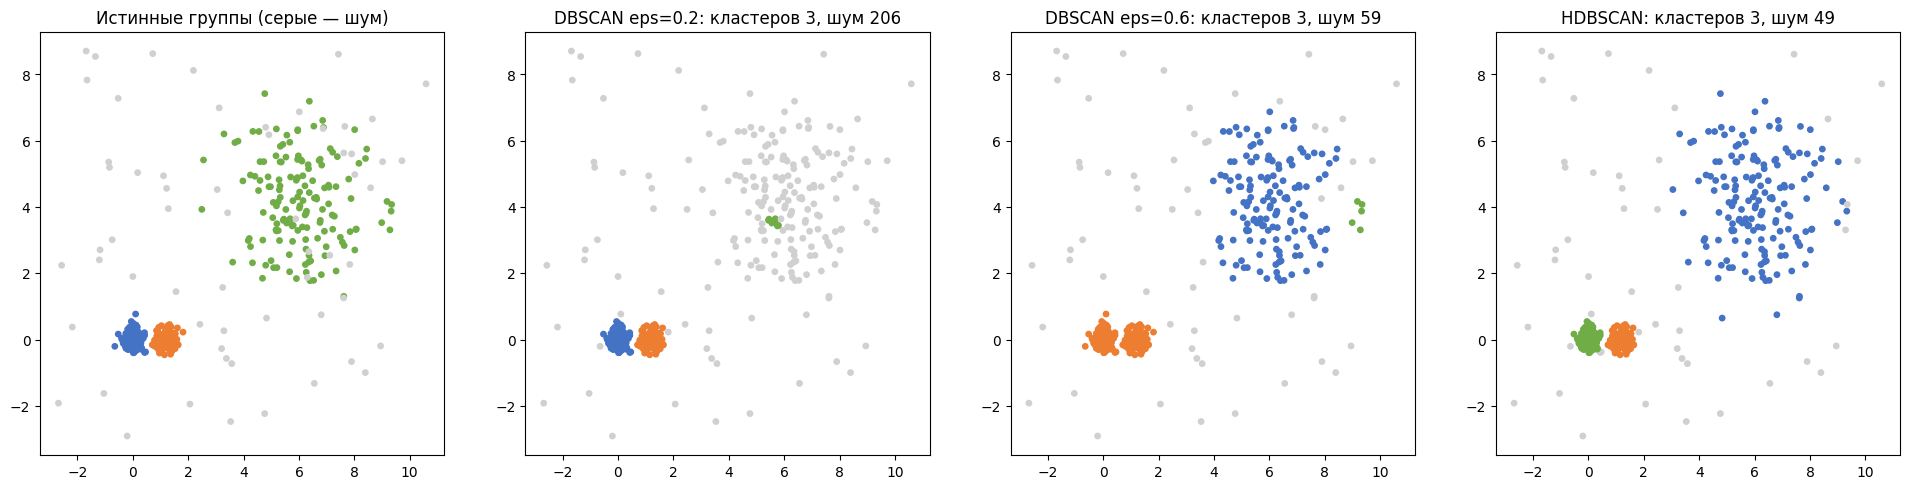

ARI HDBSCAN: 0.896


In [24]:
# copy=True указываем явно: в новых версиях sklearn иначе будет предупреждение
hdb = HDBSCAN(min_cluster_size=20, copy=True).fit(X_var)

fig, axes = plt.subplots(1, 4, figsize=(24, 5.5))
plot_clusters(X_var, y_var, ax=axes[0], title='Истинные группы (серые — шум)')
for ax, e in zip(axes[1:3], [0.2, 0.6]):
    lab = DBSCAN(eps=e, min_samples=5).fit_predict(X_var)
    plot_clusters(X_var, lab, ax=ax, title=f'DBSCAN eps={e}: кластеров {lab.max() + 1}, шум {(lab == -1).sum()}')
plot_clusters(X_var, hdb.labels_, ax=axes[3],
              title=f'HDBSCAN: кластеров {hdb.labels_.max() + 1}, шум {(hdb.labels_ == -1).sum()}')
plt.show()
print('ARI HDBSCAN:', round(adjusted_rand_score(y_var, hdb.labels_), 3))

**Что мы видим.** При маленьком `eps` (0,15–0,2) два плотных облака разделяются, но разреженное облако почти целиком (95–97 %) уходит в шум. Начиная с `eps = 0,4` плотные облака сливаются в один кластер, а разреженное облако собирается только к `eps ≈ 0,6`. Значения, при котором верно и то и другое, нет. HDBSCAN находит все три облака (ARI 0,896); в шум попали 40 из 60 настоящих шумовых точек и 9 точек с края разреженного облака.

HDBSCAN также возвращает `probabilities_` — насколько уверенно точка принадлежит своему кластеру (у шума 0).

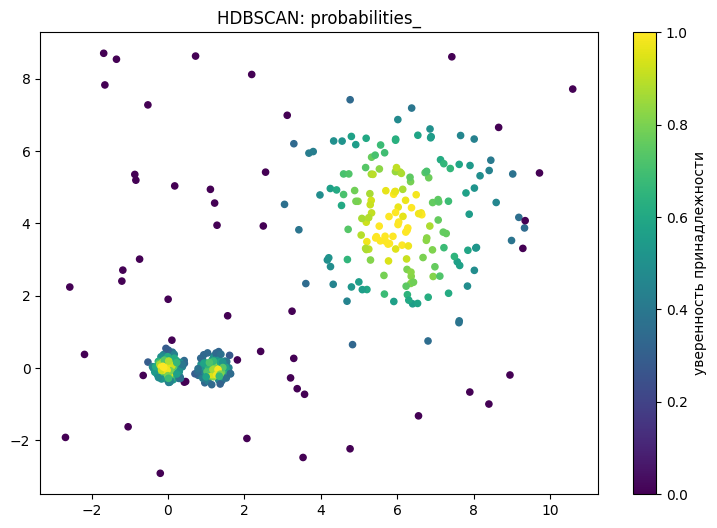

In [25]:
plt.figure(figsize=(9, 6))
sc = plt.scatter(X_var[:, 0], X_var[:, 1], c=hdb.probabilities_, cmap='viridis', s=20)
plt.colorbar(sc, label='уверенность принадлежности')
plt.title('HDBSCAN: probabilities_')
plt.show()

В центре кластеров уверенность близка к 1, на краях ниже, у шума 0. Это удобно для поиска аномалий: точки с низкой уверенностью стоит проверить отдельно.

**Вопрос.** Почему на этих данных DBSCAN не находит три кластера ни при каком одном значении `eps`?

<details>
<summary><b>Показать ответ</b></summary>

`eps` задаёт один порог плотности на всю выборку. Чтобы разделить два плотных облака, `eps` должен быть меньше зазора между ними: в таблице они сливаются уже при `eps = 0,4`. Чтобы разреженное облако стало кластером, а не шумом, `eps` должен быть порядка типичного расстояния между его точками, а это примерно 0,6. Нужные диапазоны не пересекаются.

HDBSCAN не фиксирует один `eps`: он строит иерархию кластеров для всех значений сразу и выбирает самые устойчивые. Плотные облака он берёт с «нижних» уровней иерархии (маленький `eps`), разреженное — с «верхних» (большой `eps`).

</details>

## 6. Сравнение алгоритмов на разных данных

Соберём шесть наборов данных разной формы и запустим на каждом четыре алгоритма. Перед кластеризацией признаки стандартизуем. Серые точки — шум.

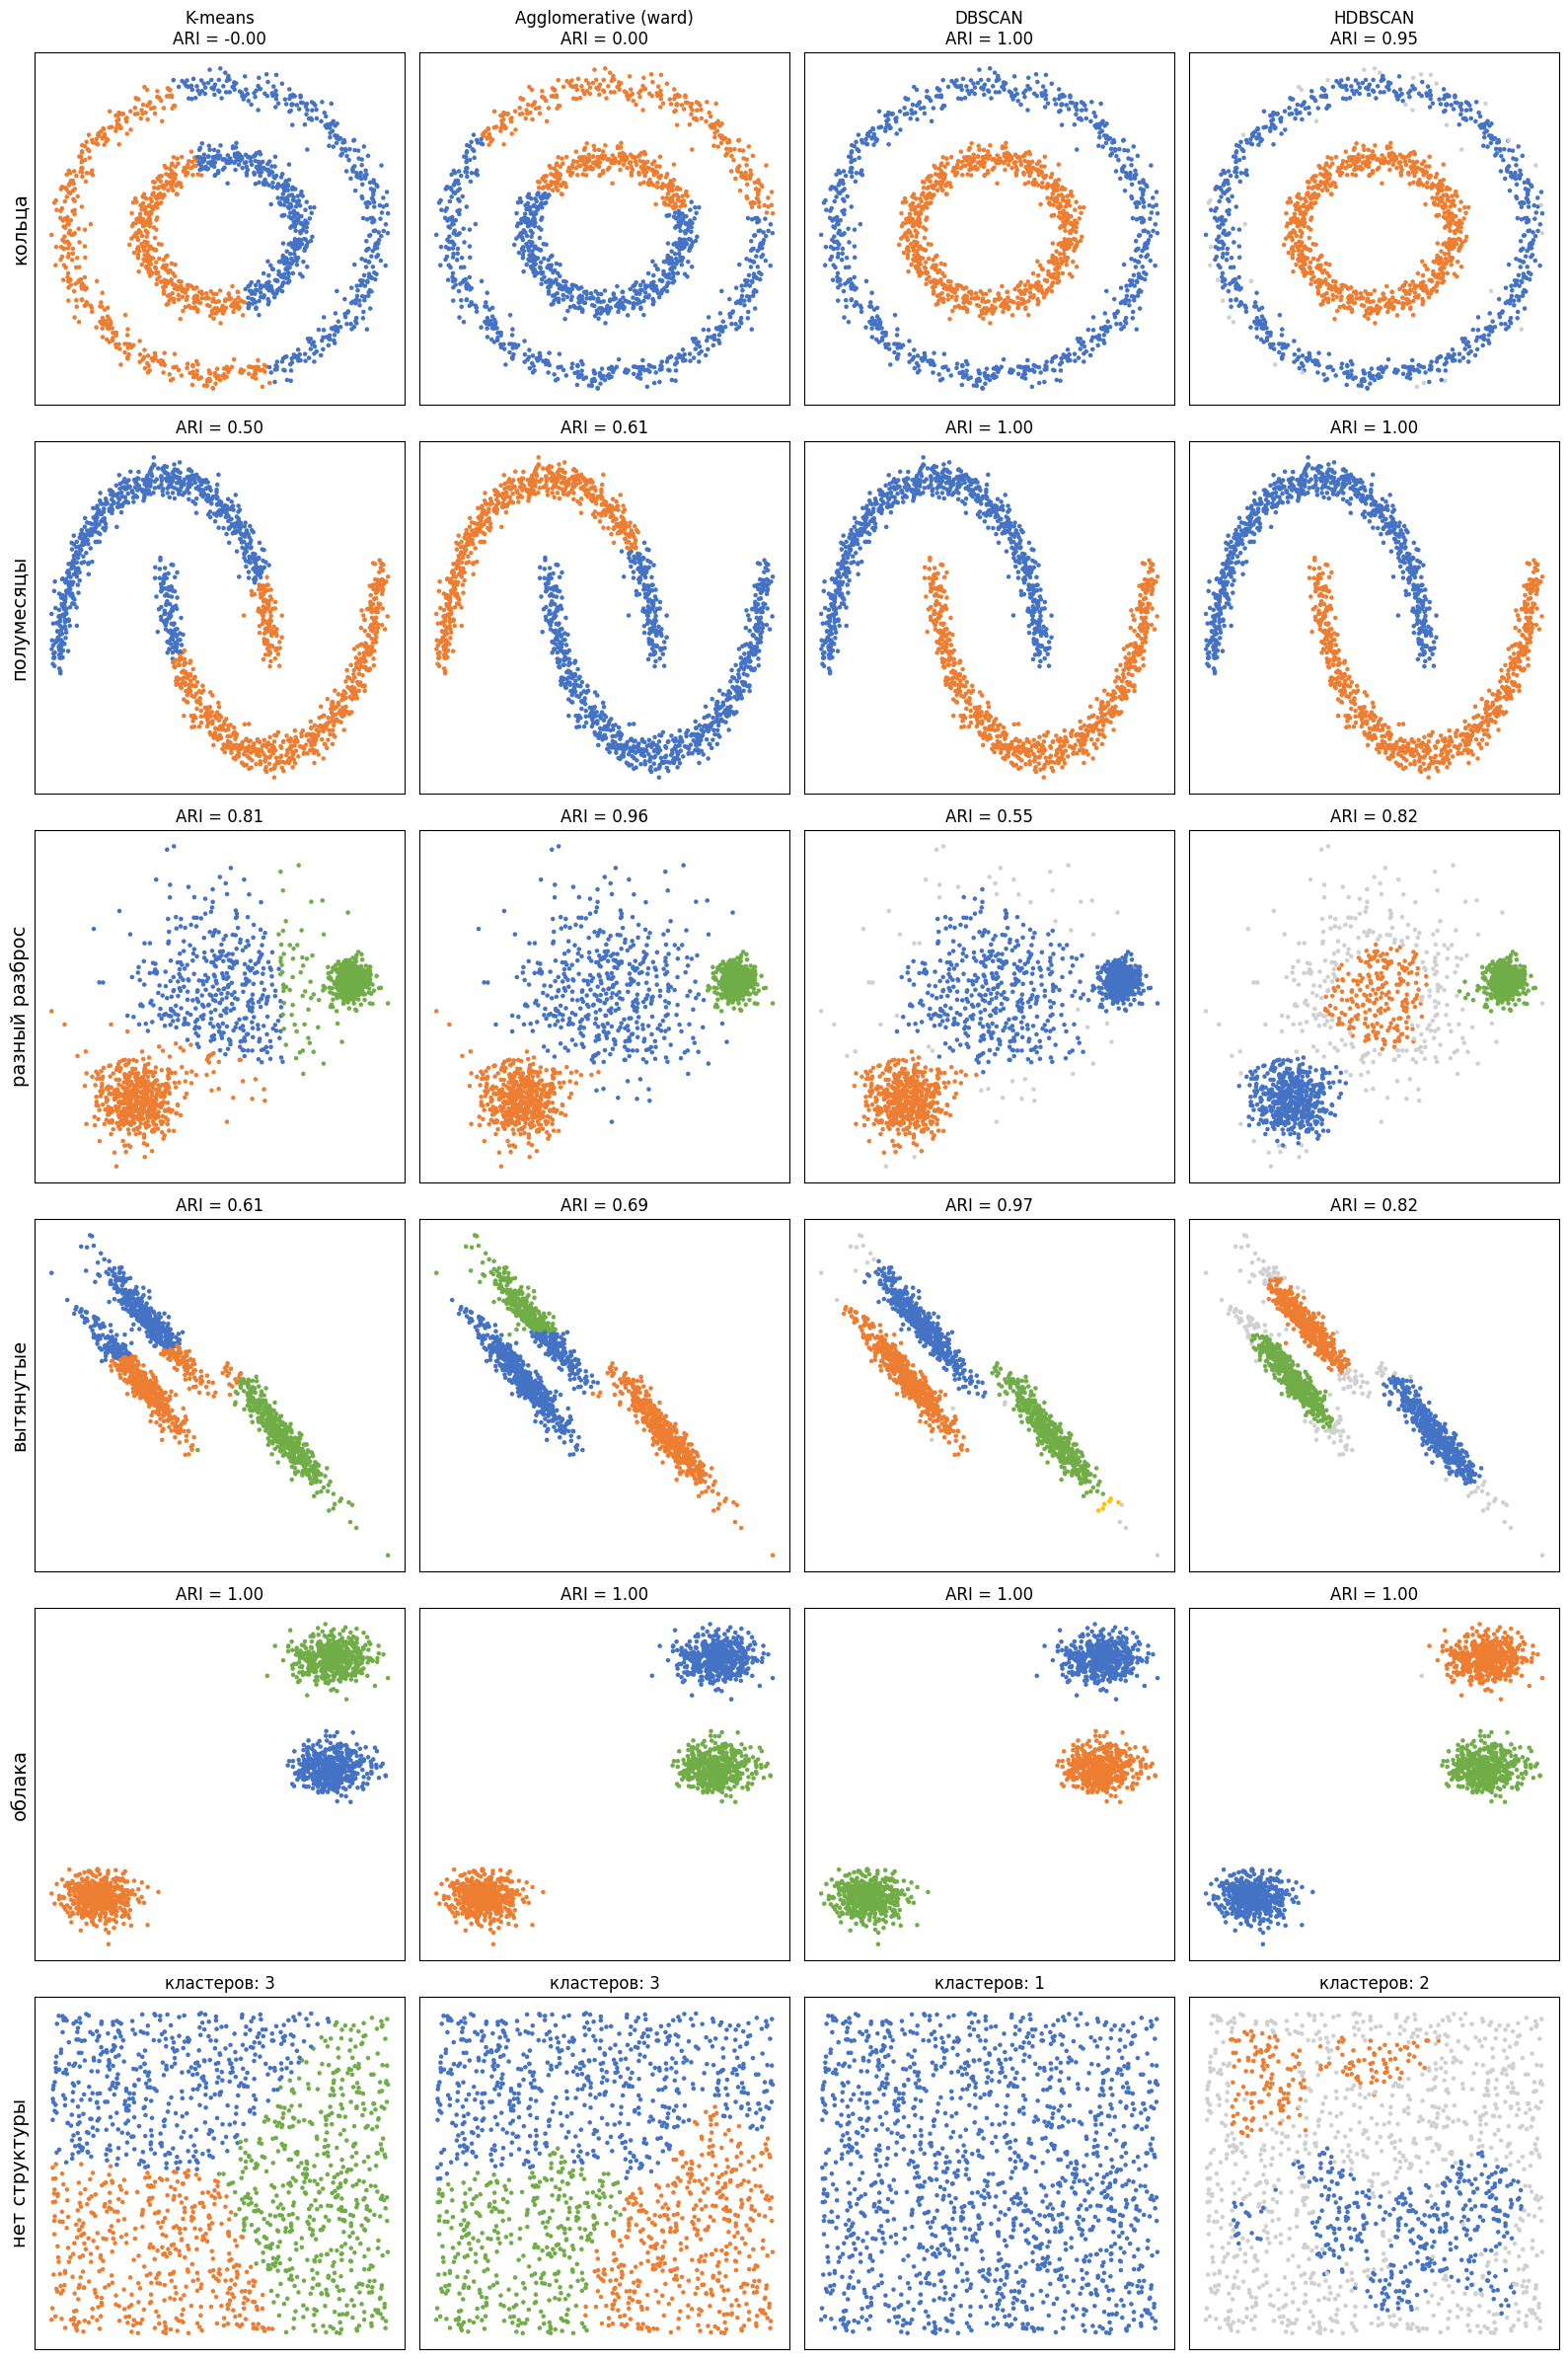

In [26]:
n = 1500
datasets = [
    ('кольца',        make_circles(n_samples=n, factor=0.5, noise=0.05, random_state=0),           {'n_clusters': 2, 'eps': 0.3}),
    ('полумесяцы',    make_moons(n_samples=n, noise=0.05, random_state=0),                         {'n_clusters': 2, 'eps': 0.3}),
    ('разный разброс', make_blobs(n_samples=n, cluster_std=[1.0, 2.5, 0.5], random_state=170),     {'n_clusters': 3, 'eps': 0.18}),
    ('вытянутые',     (make_blobs(n_samples=n, random_state=170)[0] @ [[0.6, -0.6], [-0.4, 0.8]],
                       make_blobs(n_samples=n, random_state=170)[1]),                               {'n_clusters': 3, 'eps': 0.15}),
    ('облака',        make_blobs(n_samples=n, random_state=8),                                     {'n_clusters': 3, 'eps': 0.3}),
    ('нет структуры', (np.random.default_rng(0).random((n, 2)), None),                             {'n_clusters': 3, 'eps': 0.3}),
]

fig, axes = plt.subplots(len(datasets), 4, figsize=(16, 24))
for i, (name, (Xd, yd), p) in enumerate(datasets):
    Xd = StandardScaler().fit_transform(Xd)
    algos = [
        ('K-means', KMeans(n_clusters=p['n_clusters'], n_init=10, random_state=42)),
        ('Agglomerative (ward)', AgglomerativeClustering(n_clusters=p['n_clusters'], linkage='ward')),
        ('DBSCAN', DBSCAN(eps=p['eps'], min_samples=5)),
        ('HDBSCAN', HDBSCAN(min_cluster_size=50, copy=True)),
    ]
    for j, (aname, algo) in enumerate(algos):
        lab = algo.fit_predict(Xd)
        ax = axes[i, j]
        info = f'ARI = {adjusted_rand_score(yd, lab):.2f}' if yd is not None else f'кластеров: {lab.max() + 1}'
        plot_clusters(Xd, lab, ax=ax, s=5, title=f'{aname}\n{info}' if i == 0 else info)
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(name, fontsize=14)
plt.tight_layout()
plt.show()

**Что мы видим.**

- **Кольца и полумесяцы** разделяют только DBSCAN и HDBSCAN (ARI 0,95–1,00). K-means и Уорд проводят прямую границу (ARI 0,00–0,61).
- **Облака разного разброса**: лучше всех Уорд (0,96). DBSCAN с одним `eps` объединяет часть разреженного облака с соседним (0,55), HDBSCAN относит края разреженного облака к шуму (0,82).
- **Вытянутые облака**: лучший — DBSCAN (0,97). K-means и Уорд ищут «круглые» кластеры и режут вытянутые облака поперёк (0,61 и 0,69).
- **Хорошо разделённые облака** все методы находят без ошибок.
- **Нет структуры**: K-means и Уорд всё равно режут квадрат на 3 части, DBSCAN выдаёт один кластер, HDBSCAN — 2 кластера и много шума.

Универсально лучшего алгоритма нет: выбор зависит от формы и плотности кластеров.

Сравним силуэт K-means для разных $K$ на хорошо разделённых облаках и на равномерном квадрате.

In [27]:
X_blobs = StandardScaler().fit_transform(make_blobs(n_samples=1500, random_state=8)[0])
X_unif = StandardScaler().fit_transform(np.random.default_rng(0).random((1500, 2)))

pd.DataFrame({name: {k: silhouette_score(D, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(D))
                     for k in range(2, 6)}
              for name, D in [('облака', X_blobs), ('нет структуры', X_unif)]}).round(3).rename_axis('K')

,облака,нет структуры
K,,
2,0.805,0.357
3,0.810,0.384
4,0.673,0.405
5,0.529,0.386


**Вопрос.** В последней строке точки распределены равномерно, кластеров нет. Почему K-means и иерархическая кластеризация всё равно что-то находят? Как заметить, что найденные кластеры ничего не значат?

<details>
<summary><b>Показать ответ</b></summary>

K-means и агломеративная кластеризация с заданным `n_clusters` обязаны вернуть ровно $K$ групп. Они разбивают пространство на области при любых данных, даже если групп нет. Плотностные методы (DBSCAN) в этом смысле честнее: на равномерных данных они находят один кластер.

Признаки того, что кластеры ничего не значат:

- силуэт низкий и почти не зависит от $K$: на равномерном квадрате он около 0,36–0,40 при любом $K$, а на настоящих облаках 0,81 при $K = 3$ (ячейка выше);
- на кривой инерции нет «локтя»;
- при перезапусках с разными `random_state` или на разных подвыборках границы кластеров сильно смещаются;
- кластеры не удаётся содержательно описать в терминах предметной области.

</details>

## 7. Выводы

1. **K-means** быстрый и простой, но требует заранее знать $K$, находит только выпуклые кластеры похожего размера и зависит от инициализации. Используйте `k-means++` и `n_init > 1`.
2. **Число кластеров** выбирают по излому кривой инерции, максимуму силуэта или разрезу дендрограммы. Гомогенность и инерция сами по себе улучшаются с ростом $K$, по ним одним выбирать нельзя.
3. **Масштабирование** обязательно для всех методов, основанных на расстояниях: иначе кластеры определяет признак с самым большим разбросом.
4. **DBSCAN** сам определяет число кластеров, находит кластеры сложной формы и выделяет шум. Его слабые места — подбор `eps` (помогает график k-расстояний) и кластеры разной плотности.
5. **Иерархическая кластеризация** даёт всё дерево разбиений сразу. Результат сильно зависит от способа связи: `ward` похож на K-means, `single` следует за формой данных, но склонен к цепочкам.
6. **HDBSCAN** снимает главную проблему DBSCAN: справляется с кластерами разной плотности и требует только минимальный размер кластера.
7. Алгоритм кластеризации всегда что-то найдёт. Проверяйте результат метриками, устойчивостью к перезапускам и, главное, смыслом кластеров в предметной области.